# Predicting Median Income Across Swedish Municipalities Using Regularized Regression

## Challenge Project

This project investigates whether median yearly income across Swedish municipalities can be predicted using demographic, economic, geographical, and municipality-level characteristics.

Three statistical learning methods are compared:

1. Multiple Linear Regression
2. Ridge Regression
3. Lasso Regression

Cross-validation is used to select the regularization parameters for Ridge and Lasso regression, and final predictive performance is evaluated using a held-out test set.

## 1. Introduction

Median income varies across Swedish municipalities and may be associated with differences in demographic structure, education, economic activity, transportation, and geographical characteristics.

The aim of this project is to investigate how well municipality-level characteristics can predict median yearly income and to compare ordinary multiple linear regression with two regularization methods: Ridge and Lasso regression.

The main research question is:

**How well can median income across Swedish municipalities be predicted from municipality-level characteristics, and do Ridge and Lasso regression improve predictive performance compared with ordinary linear regression?**

Multiple linear regression is used as an interpretable baseline. Ridge and Lasso regression are then used to investigate whether regularization improves predictive performance. Lasso also provides a form of variable selection by allowing some coefficients to become zero.

Model performance is evaluated using root mean squared error (RMSE) and R² on a held-out test set.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42

In [38]:
df = pd.read_excel("Project1data.xlsx")

print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

df.head()

Number of observations: 290
Number of variables: 12


,Kommun,County,Part,Coastal,Fuel,Vehicles,Builton,Seniors,Higheds,Income,GRP,PM10
0,0114 Upplands Väsby,01 Stockholms län,2,0,6.1,535.6,34,16.7,16.6,299.1,339,1.6
1,0115 Vallentuna,01 Stockholms län,2,0,12.0,780.8,90,16.1,19.2,341.5,249,2.4
2,0117 Österåker,01 Stockholms län,2,1,3.9,707.7,108,18.5,18.6,342.5,227,2.3
3,0120 Värmdö,01 Stockholms län,2,1,10.4,684.7,182,17.8,18.2,340.5,265,2.9
4,0123 Järfälla,01 Stockholms län,2,0,12.0,485.1,23,16.4,19.3,301.4,343,1.6


## 2. Data

The dataset contains observations for all 290 municipalities in Sweden. The data are from Statistics Sweden (SCB) and refer to the year 2021.

The response variable in this project is `Income`, representing median yearly income in thousands of SEK.

The available variables are:

| Variable | Description |
|---|---|
| Kommun | Municipality number and name |
| County | County number and name |
| Part | Part of Sweden: Götaland, Svealand or Norrland |
| Coastal | Inland or coastal municipality |
| Fuel | Yearly fuel consumption (GWh per 1000 inhabitants) |
| Vehicles | Passenger cars, buses and trucks per 1000 inhabitants |
| Builton | Built area (hectares per 1000 inhabitants) |
| Seniors | Percentage of inhabitants aged 65 or older |
| Higheds | Percentage with at least three years of post-secondary education |
| Income | Median yearly income (1000 SEK) |
| GRP | Gross Regional Product per capita (1000 SEK) |
| PM10 | Yearly PM10 emissions (metric tonnes per 1000 inhabitants) |

`Kommun` and `County` are identifiers and are not used as predictors.

In [39]:
df.info()

display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Kommun    290 non-null    object 
 1   County    290 non-null    object 
 2   Part      290 non-null    int64  
 3   Coastal   290 non-null    int64  
 4   Fuel      290 non-null    float64
 5   Vehicles  290 non-null    float64
 6   Builton   290 non-null    int64  
 7   Seniors   290 non-null    float64
 8   Higheds   290 non-null    float64
 9   Income    290 non-null    float64
 10  GRP       290 non-null    int64  
 11  PM10      290 non-null    float64
dtypes: float64(6), int64(4), object(2)
memory usage: 27.3+ KB


,Part,Coastal,Fuel,Vehicles,Builton,Seniors,Higheds,Income,GRP,PM10
count,290.000000,290.00000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000,290.000000
mean,1.703448,0.30000,36.474828,1024.227931,264.837931,24.406552,13.474138,289.962069,394.113793,4.968276
std,0.763566,0.45905,60.508705,317.818094,256.836028,4.744349,5.299578,24.569851,200.050056,3.110017
min,1.000000,0.00000,3.800000,366.900000,8.000000,12.800000,7.000000,256.100000,132.000000,0.900000
25%,1.000000,0.00000,14.200000,814.250000,112.000000,21.025000,9.800000,276.100000,281.250000,3.200000
50%,2.000000,0.00000,20.150000,986.800000,193.000000,24.900000,12.000000,283.500000,345.000000,4.400000
75%,2.000000,1.00000,31.775000,1160.650000,310.750000,27.900000,15.600000,294.025000,446.000000,5.900000
max,3.000000,1.00000,504.700000,2223.500000,1602.000000,37.500000,38.000000,433.000000,2159.000000,33.800000



Missing values:
Kommun      0
County      0
Part        0
Coastal     0
Fuel        0
Vehicles    0
Builton     0
Seniors     0
Higheds     0
Income      0
GRP         0
PM10        0
dtype: int64


The dataset contains 290 observations and no missing values in the variables used in this analysis. Therefore, no observations had to be removed or imputed before modelling.

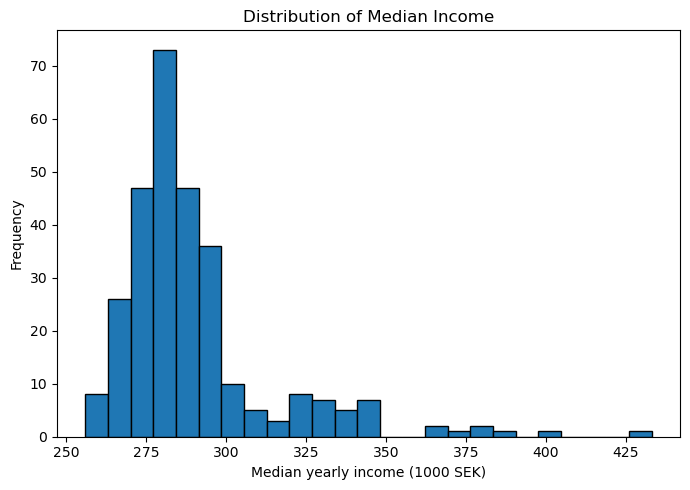

In [40]:
plt.figure(figsize=(7, 5))

plt.hist(df["Income"], bins=25, edgecolor="black")

plt.xlabel("Median yearly income (1000 SEK)")
plt.ylabel("Frequency")
plt.title("Distribution of Median Income")

plt.tight_layout()
plt.show()

### Distribution of the Response Variable

A histogram was used to examine the distribution of median yearly income across Swedish municipalities.

A histogram is appropriate here because Income is a continuous variable and the plot provides a direct view of its distribution, spread, skewness, and possible unusual observations.

Based on this distribution, Income is retained on its original scale. This also makes the prediction errors easier to interpret because the response remains measured in thousands of SEK.

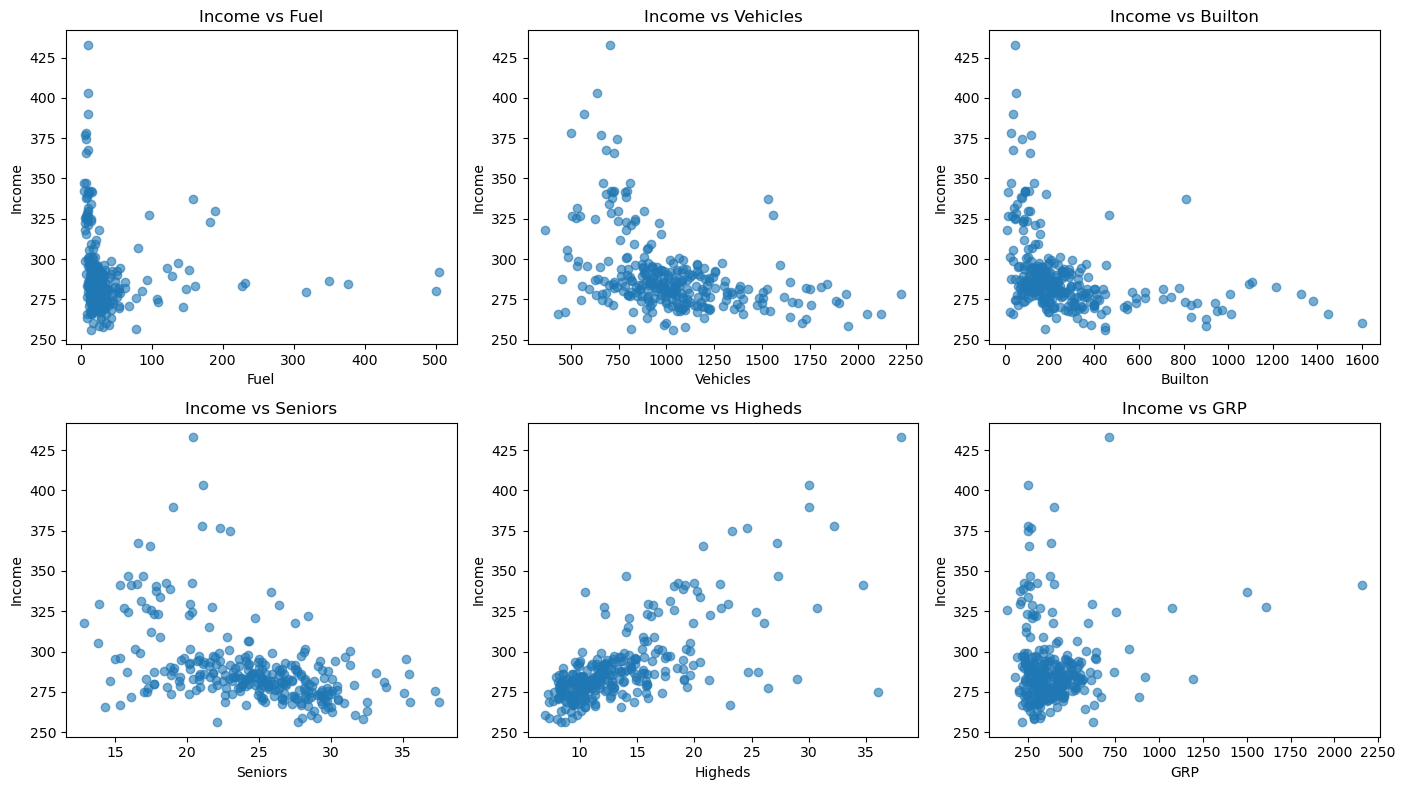

In [41]:
numeric_features = [
    "Fuel",
    "Vehicles",
    "Builton",
    "Seniors",
    "Higheds",
    "GRP"
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, variable in zip(axes.flatten(), numeric_features):
    ax.scatter(df[variable], df["Income"], alpha=0.6)
    ax.set_xlabel(variable)
    ax.set_ylabel("Income")
    ax.set_title(f"Income vs {variable}")

plt.tight_layout()
plt.show()

### Relationships with Numerical Predictors

Scatter plots were used to examine the relationships between Income and the numerical predictors.

Scatter plots are appropriate because both the response and the predictors shown here are numerical variables. They make it possible to examine the direction and strength of relationships, possible nonlinear patterns, and unusual observations.

The plots suggest that some municipality characteristics are more strongly associated with Income than others. In particular, education level, demographic structure and economic activity may contain useful predictive information.

These exploratory relationships are examined simultaneously in the statistical learning models below.

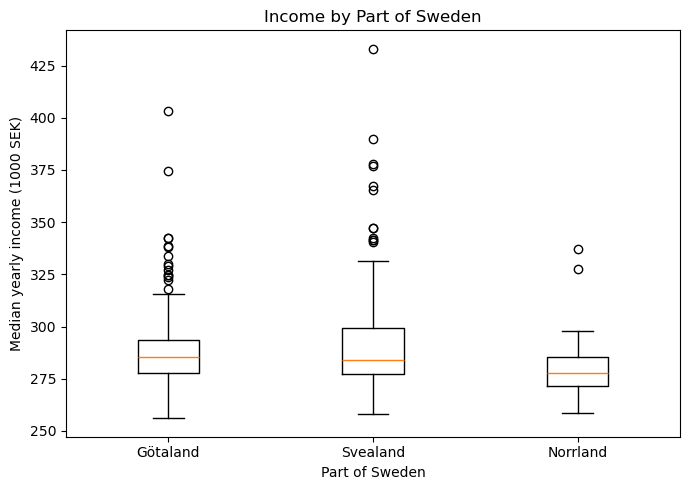

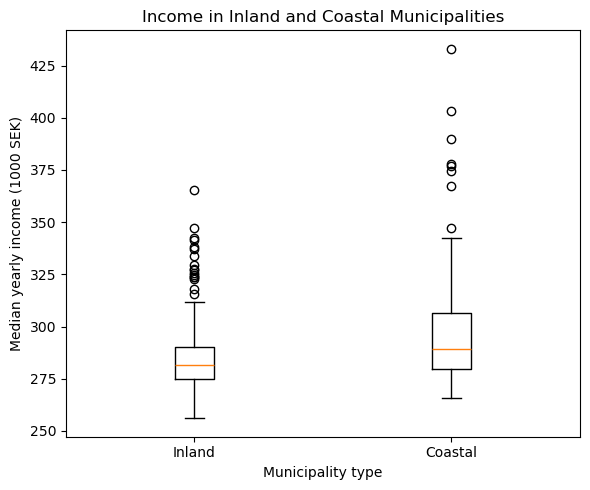

In [42]:
part_labels = {
    1: "Götaland",
    2: "Svealand",
    3: "Norrland"
}

df["Part_name"] = df["Part"].map(part_labels)

part_data = [
    df.loc[df["Part_name"] == part, "Income"]
    for part in ["Götaland", "Svealand", "Norrland"]
]

plt.figure(figsize=(7, 5))

plt.boxplot(
    part_data,
    tick_labels=["Götaland", "Svealand", "Norrland"]
)

plt.xlabel("Part of Sweden")
plt.ylabel("Median yearly income (1000 SEK)")
plt.title("Income by Part of Sweden")

plt.tight_layout()
plt.show()
coastal_data = [
    df.loc[df["Coastal"] == 0, "Income"],
    df.loc[df["Coastal"] == 1, "Income"]
]

plt.figure(figsize=(6, 5))

plt.boxplot(
    coastal_data,
    tick_labels=["Inland", "Coastal"]
)

plt.xlabel("Municipality type")
plt.ylabel("Median yearly income (1000 SEK)")
plt.title("Income in Inland and Coastal Municipalities")

plt.tight_layout()
plt.show()

### Geographical Characteristics

Boxplots were used to compare the distribution of Income across geographical categories.

Unlike scatter plots, boxplots are appropriate when comparing a continuous response variable with categorical predictors. They display differences in the median, spread, and possible outliers between groups.

The first plot compares municipalities in Götaland, Svealand and Norrland, while the second compares inland and coastal municipalities.

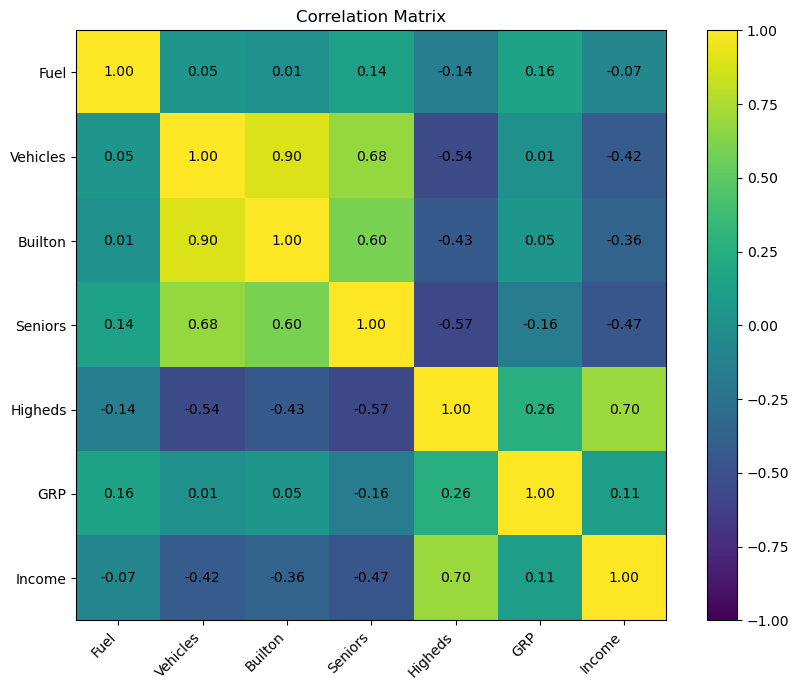

In [43]:
corr_variables = numeric_features + ["Income"]

corr = df[corr_variables].corr()

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr, vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))

ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

The correlation matrix summarizes the pairwise linear relationships between the numerical variables.

It is useful for identifying predictors that are associated with Income and for detecting correlations among the predictors themselves. Correlation among predictors is particularly relevant when comparing ordinary linear regression with regularized methods such as Ridge and Lasso.

## 3. Data Preparation

The response variable is median yearly Income.

Six numerical predictors are included:

- Fuel
- Vehicles
- Builton
- Seniors
- Higheds
- GRP

Two geographical categorical predictors are also included:

- Part
- Coastal

`Kommun` and `County` are excluded because they primarily identify individual municipalities and counties rather than representing numerical municipality characteristics.

For modelling, numerical predictors are standardized to have comparable scales. This is particularly important for Ridge and Lasso regression because their penalties depend on the magnitude of the coefficients.

The categorical variable `Part` is converted into dummy variables. `Coastal` is already represented as a binary 0/1 variable.

In [44]:
numeric_features = [
    "Fuel",
    "Vehicles",
    "Builton",
    "Seniors",
    "Higheds",
    "GRP"
]

categorical_features = ["Part"]

features = numeric_features + categorical_features + ["Coastal"]

X = df[features]
y = df["Income"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 232
Test observations: 58


In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

## 4. Statistical Learning Methods

### Multiple Linear Regression

Multiple linear regression is used as a baseline. It provides a simple and interpretable model against which the regularized models can be compared.

### Ridge Regression

Ridge regression adds an L2 penalty to the ordinary least squares objective. The penalty shrinks coefficients towards zero and can improve prediction when predictors are correlated or when ordinary regression estimates have high variance.

### Lasso Regression

Lasso regression uses an L1 penalty. In addition to shrinking coefficients, Lasso can reduce some coefficients exactly to zero. It therefore provides a form of automatic variable selection.

### Cross-Validation

The amount of regularization is controlled by the parameter alpha. Ten-fold cross-validation is used on the training data to select alpha for Ridge and Lasso regression.

The held-out test set is not used during model selection. It is used only for the final comparison of predictive performance.

Model performance is evaluated using:

- **RMSE:** measures the typical magnitude of prediction errors. Lower values indicate better prediction.
- **R²:** measures how much variation in Income is explained by the predictions. Higher values indicate better predictive performance.

In [46]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

pred_linear = linear_model.predict(X_test)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, pred_linear)
)

r2_linear = r2_score(
    y_test,
    pred_linear
)

print("Linear Regression")
print("Test RMSE:", round(rmse_linear, 3))
print("Test R²:", round(r2_linear, 3))

Linear Regression
Test RMSE: 20.913
Test R²: 0.053


In [47]:
alphas = np.logspace(-4, 4, 200)

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RidgeCV(
        alphas=alphas,
        cv=10
    ))
])

ridge_model.fit(X_train, y_train)

pred_ridge = ridge_model.predict(X_test)

rmse_ridge = np.sqrt(
    mean_squared_error(y_test, pred_ridge)
)

r2_ridge = r2_score(
    y_test,
    pred_ridge
)

best_alpha_ridge = ridge_model.named_steps["model"].alpha_

print("Ridge Regression")
print("Best alpha:", round(best_alpha_ridge, 4))
print("Test RMSE:", round(rmse_ridge, 3))
print("Test R²:", round(r2_ridge, 3))

Ridge Regression
Best alpha: 12.7505
Test RMSE: 19.989
Test R²: 0.135


In [48]:
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LassoCV(
        alphas=alphas,
        cv=10,
        max_iter=100000,
        random_state=RANDOM_STATE
    ))
])

lasso_model.fit(X_train, y_train)

pred_lasso = lasso_model.predict(X_test)

rmse_lasso = np.sqrt(
    mean_squared_error(y_test, pred_lasso)
)

r2_lasso = r2_score(
    y_test,
    pred_lasso
)

best_alpha_lasso = lasso_model.named_steps["model"].alpha_

print("Lasso Regression")
print("Best alpha:", round(best_alpha_lasso, 4))
print("Test RMSE:", round(rmse_lasso, 3))
print("Test R²:", round(r2_lasso, 3))

Lasso Regression
Best alpha: 0.0311
Test RMSE: 20.826
Test R²: 0.061


In [49]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "Test RMSE": [
        rmse_linear,
        rmse_ridge,
        rmse_lasso
    ],
    "Test R2": [
        r2_linear,
        r2_ridge,
        r2_lasso
    ]
})

results.round(3)

,Model,Test RMSE,Test R2
0,Linear Regression,20.913,0.053
1,Ridge Regression,19.989,0.135
2,Lasso Regression,20.826,0.061


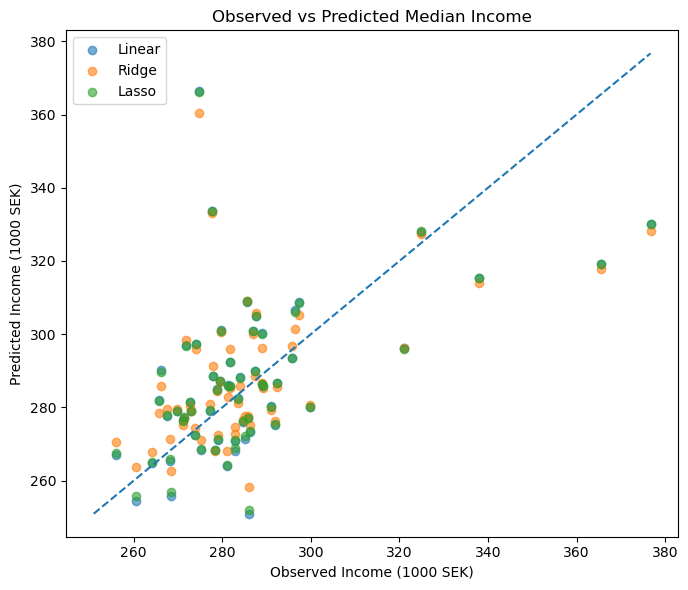

In [50]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    pred_linear,
    alpha=0.6,
    label="Linear"
)

plt.scatter(
    y_test,
    pred_ridge,
    alpha=0.6,
    label="Ridge"
)

plt.scatter(
    y_test,
    pred_lasso,
    alpha=0.6,
    label="Lasso"
)

minimum = min(
    y_test.min(),
    pred_linear.min(),
    pred_ridge.min(),
    pred_lasso.min()
)

maximum = max(
    y_test.max(),
    pred_linear.max(),
    pred_ridge.max(),
    pred_lasso.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Observed Income (1000 SEK)")
plt.ylabel("Predicted Income (1000 SEK)")
plt.title("Observed vs Predicted Median Income")

plt.legend()
plt.tight_layout()
plt.show()

The observed-versus-predicted plot provides a direct visual assessment of prediction accuracy.

The dashed diagonal line represents perfect predictions. Points close to this line indicate that predicted Income is close to the observed value.

Plotting all three models together also makes it possible to visually compare their predictions.

In [51]:
feature_names = (
    lasso_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

lasso_coefs = (
    lasso_model
    .named_steps["model"]
    .coef_
)

lasso_coefficients = pd.DataFrame({
    "Variable": feature_names,
    "Coefficient": lasso_coefs
})

lasso_coefficients["Absolute coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)

lasso_coefficients = lasso_coefficients.sort_values(
    "Absolute coefficient",
    ascending=False
)

lasso_coefficients

,Variable,Coefficient,Absolute coefficient
4,num__Higheds,18.521857,18.521857
1,num__Vehicles,9.585897,9.585897
7,cat__Part_3,-8.754785,8.754785
8,remainder__Coastal,4.993827,4.993827
3,num__Seniors,-4.740400,4.740400
2,num__Builton,-4.474291,4.474291
6,cat__Part_2,2.168357,2.168357
5,num__GRP,-1.997601,1.997601
0,num__Fuel,1.323618,1.323618


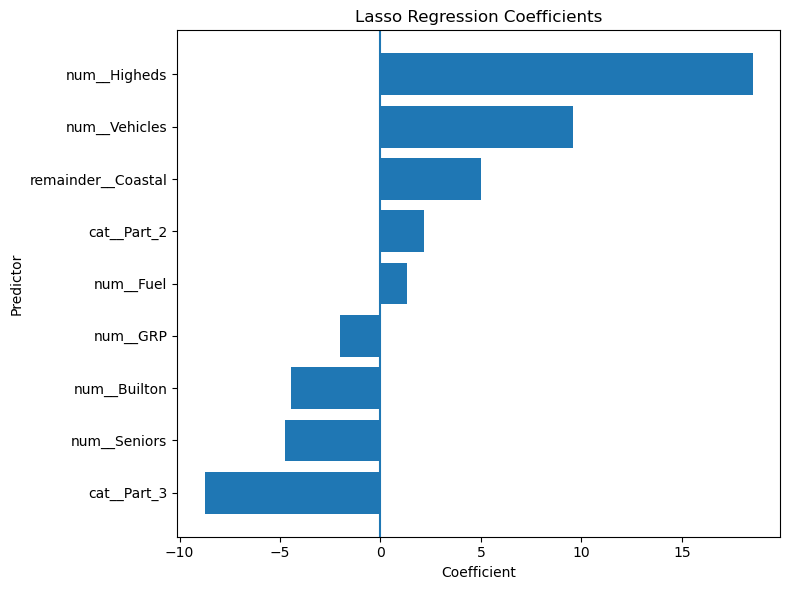

In [52]:
plot_data = lasso_coefficients.sort_values(
    "Coefficient"
)

plt.figure(figsize=(8, 6))

plt.barh(
    plot_data["Variable"],
    plot_data["Coefficient"]
)

plt.axvline(0)

plt.xlabel("Coefficient")
plt.ylabel("Predictor")
plt.title("Lasso Regression Coefficients")

plt.tight_layout()
plt.show()

The Lasso coefficient plot shows the direction and relative magnitude of the coefficients retained by the model.

Among the standardized numerical predictors, `Higheds` has the largest positive coefficient, suggesting that the percentage of inhabitants with at least three years of post-secondary education provides particularly useful predictive information for median income. `Vehicles` also has a relatively large positive coefficient.

The coefficient for Norrland (`Part_3`) is negative relative to the reference category, Götaland. `Seniors` and `Builton` also have negative coefficients, while `Coastal` has a positive coefficient.

At the regularization level selected by ten-fold cross-validation, Lasso did not reduce any of the included coefficients exactly to zero. Therefore, in this particular analysis, Lasso applied shrinkage but did not perform complete variable exclusion.

These coefficients describe predictive associations after accounting for the other variables and should not be interpreted as causal effects.

## 5. Discussion and Limitations

Among the three models, Ridge regression achieved the best predictive performance on the held-out test set. Its RMSE of 19.989 was lower than the RMSE of 20.913 for ordinary linear regression and 20.826 for Lasso regression. Ridge also achieved the highest test R² of 0.135.

The improvement from Ridge regression suggests that coefficient shrinkage is useful for this dataset. Several municipality characteristics contain overlapping information, and Ridge regression can reduce the variance of coefficient estimates when predictors are correlated.

Lasso regression provided only a small improvement over ordinary linear regression. At the value of alpha selected by cross-validation, none of the coefficients were reduced exactly to zero. This suggests that completely removing predictors did not provide a substantial advantage for this prediction problem.

The relatively low R² values are an important limitation. Even the best model explains only a limited proportion of the variation in Income in the test data. This indicates that the available predictors do not capture many factors that determine differences in median income between municipalities.

There are several additional limitations.

First, the dataset contains 290 municipalities. Although these represent all Swedish municipalities, the number of observations available for statistical learning is relatively small.

Second, all variables refer to 2021. The relationships identified here may differ in other years as economic conditions and income levels change.

Third, the dataset contains only a limited set of municipality-level characteristics. Income may depend on important factors that are not included, such as occupation, unemployment, industry composition, housing costs, commuting patterns and proximity to major labour markets.

Fourth, municipalities are treated as independent observations. In reality, neighbouring municipalities may share labour markets, infrastructure and economic conditions, creating spatial dependence that is not represented by these models.

Finally, these results describe predictive associations rather than causal relationships. For example, the large positive coefficient for higher education does not demonstrate that increasing the proportion of highly educated inhabitants would directly cause median income to increase.

Linear, Ridge and Lasso regression also primarily represent linear relationships. Nonlinear relationships and interactions between municipality characteristics may therefore not be fully captured.

## 6. FAIR Principles

The FAIR principles describe how research data and workflows can be made Findable, Accessible, Interoperable and Reusable.

### Findable

The project uses clear file names and a documented folder structure. The README describes the research question, data source, variables and analysis. The source of the municipality data, Statistics Sweden (SCB), is documented.

### Accessible

The complete analysis is provided in a Jupyter Notebook that can be opened using freely available software. Information about the source of the data and the files required to reproduce the analysis is documented in the repository.

### Interoperable

The data are stored in a standard tabular format and the analysis uses widely adopted Python libraries such as pandas, NumPy, Matplotlib and scikit-learn. The data can also be converted to other common tabular formats such as CSV.

### Reusable

The complete workflow from data preparation to model evaluation is documented in the notebook. Variable definitions, modelling decisions and software dependencies are provided. A requirements file records the Python dependencies, and a license specifies how the project code can be reused.

## 7. Reproducibility

The complete statistical analysis is implemented in Python in this Jupyter Notebook.

A fixed random seed (`random_state = 42`) is used for the train-test split and relevant modelling procedures. This ensures that the same training and test observations are obtained when the analysis is repeated.

The regularized models use ten-fold cross-validation on the training data to select their regularization parameters.

The software dependencies and package versions required to reproduce the analysis are documented in `requirements.txt`.

The project repository contains:

- `Income_project.ipynb` — complete analysis
- `Project1data.xlsx` — input dataset
- `README.md` — project and data documentation
- `requirements.txt` — Python dependencies and versions
- `LICENSE` — software license

## 8. Conclusion

This project investigated whether median yearly income across Swedish municipalities can be predicted from demographic, economic and geographical municipality characteristics.

Three statistical learning methods were compared: ordinary multiple linear regression, Ridge regression and Lasso regression. Ten-fold cross-validation was used to select the regularization parameters, and predictive performance was evaluated on a separate test set using RMSE and R².

Ridge regression achieved the best predictive performance, with a test RMSE of 19.989 and an R² of 0.135. This was an improvement over ordinary linear regression, which obtained an RMSE of 20.913 and an R² of 0.053. Lasso regression performed only slightly better than ordinary linear regression, with an RMSE of 20.826 and an R² of 0.061.

The relatively low test R² values indicate that the available municipality characteristics explain only a limited proportion of the variation in median income in the held-out municipalities. This suggests that important predictors of municipality-level income are not included in the dataset.

Among the predictors in the Lasso model, the percentage of inhabitants with at least three years of post-secondary education (`Higheds`) had the largest positive standardized coefficient. However, Lasso did not reduce any of the included coefficients exactly to zero at the regularization level selected by cross-validation.

Overall, Ridge regression provided the best predictions among the three models, although the overall predictive performance remained limited. The project demonstrates how regularization and cross-validation can be incorporated into a reproducible statistical learning workflow.

In [53]:
import sklearn
import matplotlib
import openpyxl

print("Python package versions:")
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)
print("openpyxl:", openpyxl.__version__)

Python package versions:
numpy: 2.3.1
pandas: 2.3.3
matplotlib: 3.10.6
scikit-learn: 1.7.2
openpyxl: 3.1.5
